# Model evaluation

How good is the trained network, and compared with what?

- The model picks its highest-scored move (no randomness).
- It sees only what a player would see.
- Every test uses shuffles (seeds) that were never used in training or in the tests shown during training.
- Each matchup is split evenly between the two decks and the two seats. The intervals are 95%.

This notebook takes several minutes to run.

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from tcg_bot.model.net import Net, load
from tcg_bot.model.player import MATCHUPS, Game, play

torch.set_num_threads(1)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
MODEL = ROOT / "models" / "first"
EARLIER = ROOT / "models" / "first_239"
SEED = 2_000_000_000
N, N_BASE = 2000, 1000
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8a85"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "axes.axisbelow": True})

model = load(MODEL)

In [2]:
def match(player, opponent, n, net=None, past=None, seed=SEED):
    """n games between two controllers ("learner", "past", "stand_in", "random"). One row per game."""
    batch = []
    for i in range(n):
        seat = (i // 2) % 2
        seats = (player, opponent) if seat == 0 else (opponent, player)
        batch.append(Game(seed=seed + i, decks=MATCHUPS[i % 2], seats=seats))
    rows, decisions = [], []
    for start in range(0, n, 100):
        for i, g in enumerate(play(batch[start:start + 100], net, past=past, greedy=True), start):
            seat = (i // 2) % 2
            result = "draw" if g.state.winner is None else ("win" if g.state.winner == seat else "loss")
            rows.append({"deck": g.decks[seat], "went_first": g.state.first_player == seat, "result": result,
                         "turns": g.state.turn, "end": g.state.end_reason})
            if player == "learner":
                steps = g.steps[seat]
                decisions += [{"game": i, "progress": k / len(steps), "value": s.value, "won": result == "win",
                               "draw": result == "draw"} for k, s in enumerate(steps)]
    return pd.DataFrame(rows), pd.DataFrame(decisions)


def rate(games):
    n, p = len(games), (games["result"] == "win").mean()
    return {"games": n, "win rate": p, "95% ±": 1.96 * math.sqrt(p * (1 - p) / n)}


def as_percent(table, columns):
    return table.style.format({c: "{:.1%}" for c in columns})

## 1. Training curve

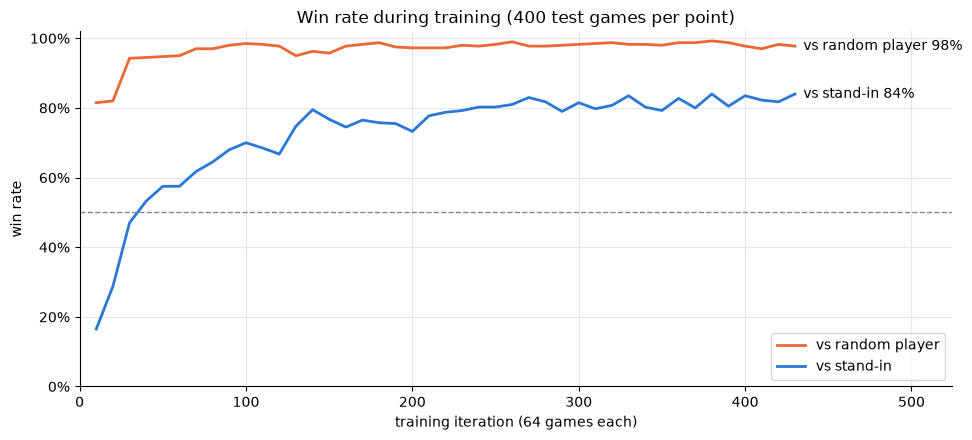

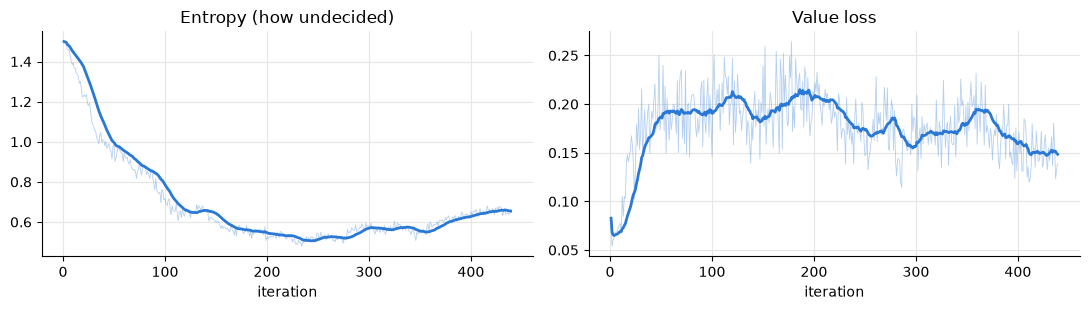

average win rate vs stand-in, by block of 80 iterations:
block
1      48.3%
81     72.3%
161    77.1%
241    80.9%
321    81.7%
401    82.7%


In [3]:
metrics = pd.read_csv(MODEL / "metrics.csv")
tests = metrics.dropna(subset=["eval_stand_in"])

fig, ax = plt.subplots(figsize=(10, 4.5))
for column, label, colour in (("eval_random", "vs random player", ORANGE), ("eval_stand_in", "vs stand-in", BLUE)):
    ax.plot(tests["iteration"], tests[column], color=colour, lw=2, label=label)
    last = tests.iloc[-1]
    ax.annotate(f"{label} {last[column]:.0%}", (last["iteration"], last[column]), xytext=(6, 0),
                textcoords="offset points", va="center")
ax.axhline(0.5, color=GREY, lw=1, ls="--")
ax.set_ylim(0, 1.02); ax.set_xlim(0, tests["iteration"].max() * 1.22)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("training iteration (64 games each)"); ax.set_ylabel("win rate")
ax.set_title("Win rate during training (400 test games per point)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, column, title in zip(axes, ["entropy", "value_loss"], ["Entropy (how undecided)", "Value loss"]):
    ax.plot(metrics["iteration"], metrics[column], color=BLUE, lw=0.6, alpha=0.35)
    ax.plot(metrics["iteration"], metrics[column].rolling(20, min_periods=1).mean(), color=BLUE, lw=2)
    ax.set_title(title); ax.set_xlabel("iteration")
plt.tight_layout(); plt.show()

blocks = tests.assign(block=((tests["iteration"] - 1) // 80) * 80 + 1).groupby("block")["eval_stand_in"].mean()
print("average win rate vs stand-in, by block of 80 iterations:")
print(blocks.map("{:.1%}".format).to_string())

**Reading it.** The win rate against the stand-in rises from 17% at iteration 10 to about 80% by iteration 240, then climbs only slowly (block averages 80.9%, 81.7%, 82.7%). Entropy falls until about iteration 250 and then drifts up a little. Value loss does not fall steadily: it rises early and stays around 0.15 to 0.2.

These curves use the same 400 test shuffles every time, so they are for watching progress. Section 2 gives the result to report.

## 2. Final test on unseen games

In [4]:
vs_stand_in, decisions = match("learner", "stand_in", N, net=model)
vs_random, _ = match("learner", "random", N, net=model)
final = pd.DataFrame({"vs stand-in": rate(vs_stand_in), "vs random": rate(vs_random)}).T
as_percent(final, ["win rate", "95% ±"]).format({"games": "{:.0f}"}, subset=["games"])

,games,win rate,95% ±
vs stand-in,2000,82.2%,1.7%
vs random,2000,98.7%,0.5%


## 3. Compared with what?

A win rate means little alone. The same test for an untrained network (random weights), the stand-in itself and a random player.

In [5]:
torch.manual_seed(0)
untrained = Net().eval()
players = {"trained network": ("learner", model), "untrained network": ("learner", untrained),
           "stand-in": ("stand_in", None), "random player": ("random", None)}
rows = {}
for name, (controller, net) in players.items():
    for opponent, label in (("stand_in", "vs stand-in"), ("random", "vs random")):
        games, _ = match(controller, opponent, N_BASE, net=net)
        r = rate(games)
        rows.setdefault(name, {})[label] = r["win rate"]
        rows[name][label + " ±"] = r["95% ±"]
baselines = pd.DataFrame(rows).T

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(baselines.index, baselines["vs stand-in"], xerr=baselines["vs stand-in ±"], color=BLUE, height=0.55)
for y, v in enumerate(baselines["vs stand-in"]):
    ax.text(v + baselines["vs stand-in ±"].iloc[y] + 0.012, y, f"{v:.0%}", va="center")
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.axvline(0.5, color=GREY, lw=1, ls="--")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title(f"Win rate against the stand-in ({N_BASE} games each)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
as_percent(baselines, list(baselines.columns))

KeyboardInterrupt: 

**Reading it.** The trained network wins about 81% against the stand-in, where the stand-in itself wins 48% in the same position. The untrained network and the random player both win about 17%. So the gain comes from training, not from the shape of the network or the list of legal moves.

An untrained network still beats a random player 66% of the time: always taking its own top choice is more consistent than choosing at random.

## 4. By deck and by who went first (against the stand-in)

In [ ]:
split = vs_stand_in.assign(win=vs_stand_in["result"] == "win",
                           order=vs_stand_in["went_first"].map({True: "went first", False: "went second"}))
by = split.pivot_table(index="deck", columns="order", values="win", aggfunc="mean")
by["both"] = split.groupby("deck")["win"].mean()
print(f"about {len(split) // 4} games per deck and turn order")
as_percent(by, list(by.columns))

about 500 games per deck and turn order


order,went first,went second,both
deck,,,
lopunny,75.9%,75.5%,75.7%
mega_lucario,90.1%,87.0%,88.6%


**Reading it.** The deck matters much more than going first: about 89% as Mega Lucario against 76% as Lopunny, while going first or second changes the result by only about 3 points at most. This does not show which deck is stronger in real play, only how well this network plays each against this opponent.

## 5. Against an earlier copy of itself

The stand-in is weak and the model trained against it, so it is also tested against its own state at iteration 239.

In [ ]:
if (EARLIER / "model.pt").exists():
    head, _ = match("learner", "past", N, net=model, past=load(EARLIER))
    print({k: (f"{v:.1%}" if k != "games" else v) for k, v in rate(head).items()}, "(final model against iteration 239)")
    print(head.assign(win=head["result"] == "win").groupby("deck")["win"].mean().map("{:.1%}".format).to_string())
else:
    print("no earlier copy in", EARLIER)

{'games': 2000, 'win rate': '56.2%', '95% ±': '2.2%'} (final model against iteration 239)
deck
lopunny         43.6%
mega_lucario    68.8%


**Reading it.** The final model beats its iteration-239 copy 56% of the time, so the last 200 iterations still helped, though modestly. Here the deck effect is the same as above (69% as Mega Lucario, 44% as Lopunny); because each deck is used equally, the 56% overall is the fair number.

## 6. How games end

In [ ]:
stand_in_mirror, _ = match("stand_in", "stand_in", N_BASE)
ends = pd.DataFrame({"model vs stand-in": vs_stand_in["end"].value_counts(normalize=True),
                     "stand-in vs stand-in": stand_in_mirror["end"].value_counts(normalize=True)}).fillna(0)
print("median turns:", int(vs_stand_in["turns"].median()), "(model) |", int(stand_in_mirror["turns"].median()),
      "(stand-in against itself)")
as_percent(ends, list(ends.columns))

median turns: 20 (model) | 25 (stand-in against itself)


,model vs stand-in,stand-in vs stand-in
end,,
deck_out,5.2%,12.8%
no_pokemon,8.9%,2.8%
prizes,85.8%,84.4%
sudden_death,0.1%,0.0%


**Reading it.** Most of the model's games against the stand-in end by taking all Prize cards (86%). Few end by running out of cards (5%, against 13% when the stand-in plays itself), and its games are shorter (median 20 turns against 25).

## 7. Does the network know who is winning?

Besides scoring moves, the network estimates how the game is going (its *value*, from -1 to +1). Here "value above 0" is read as
"I will win" and compared with what happened, at every decision it made in the games of section 2. Draws are left out.

In [ ]:
d = decisions[~decisions["draw"]].copy()
d["predicted"] = d["value"] > 0

def scores(x):
    tp = (x["predicted"] & x["won"]).sum(); fp = (x["predicted"] & ~x["won"]).sum()
    tn = (~x["predicted"] & ~x["won"]).sum(); fn = (~x["predicted"] & x["won"]).sum()
    return {"decisions": len(x), "accuracy": (tp + tn) / len(x), "precision": tp / (tp + fp),
            "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
            "always saying 'win'": x["won"].mean()}

stage = pd.cut(d["progress"], [-0.01, 1 / 3, 2 / 3, 1], labels=["early", "middle", "late"])
quality = pd.DataFrame({"all decisions": scores(d), **{s: scores(d[stage == s]) for s in ["early", "middle", "late"]}}).T
as_percent(quality, [c for c in quality.columns if c != "decisions"]).format({"decisions": "{:.0f}"}, subset=["decisions"])

,decisions,accuracy,precision,sensitivity,specificity,always saying 'win'
all decisions,116597,79.5%,88.3%,85.7%,54.3%,80.1%
early,40200,72.0%,84.3%,80.1%,39.7%,80.2%
middle,38859,80.2%,88.2%,86.9%,53.2%,80.1%
late,37538,86.6%,92.6%,90.5%,71.1%,80.1%


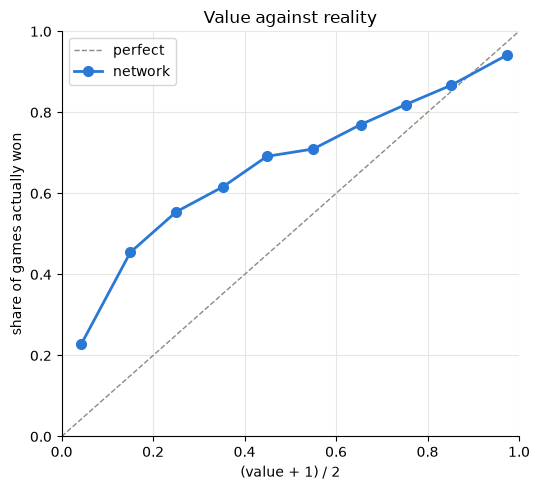

,predicted,won,decisions
0,0.043,0.227,5307
1,0.150,0.455,4311
2,0.251,0.555,4906
3,0.353,0.616,5570
4,0.449,0.692,5858
5,0.550,0.710,5934
6,0.654,0.770,7511
7,0.752,0.819,12123
8,0.852,0.867,15505
9,0.974,0.942,49572


In [ ]:
bins = pd.cut((d["value"] + 1) / 2, [i / 10 for i in range(11)], include_lowest=True)
calibration = d.assign(p=(d["value"] + 1) / 2).groupby(bins, observed=True).agg(predicted=("p", "mean"), won=("won", "mean"),
                                                                              decisions=("won", "size"))
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=GREY, lw=1, ls="--", label="perfect")
ax.plot(calibration["predicted"], calibration["won"], color=BLUE, lw=2, marker="o", ms=7, label="network")
ax.set_xlabel("(value + 1) / 2"); ax.set_ylabel("share of games actually won"); ax.set_title("Value against reality")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc="upper left"); plt.tight_layout(); plt.show()
calibration.reset_index(drop=True).round(3)

**Reading it.** Do not report the 79.5% accuracy on its own: **always answering "win" would score 80.1%**, because the model wins most of its games. Early in a game the value is worse than that (72%); late in a game it is better (87%). Precision is 88% and sensitivity 86%, but specificity is only 54%: it often fails to see a loss coming.

The chart shows the network is too pessimistic at low values: when it suggests about a 4% chance, it actually wins 23% of the time. A likely reason, not tested here, is that it learned its value partly from games against itself, where winning is a coin toss.

Decisions from the same game are not independent, so these numbers are less certain than the count of decisions suggests.

## 8. What this does and does not show

**Shown**
- The trained network is far better than an untrained one, a random player and the stand-in, against those same opponents.
- It improves on its own earlier copy.

**Not shown**
- **That it plays well.** The stand-in follows a few fixed habits and was part of training, so beating it may partly mean exploiting it. No human or stronger player has been measured.
- **That the PCA helps.** No version without the PCA numbers has been trained. This needs the ablation: PCA plus identity, identity only, PCA only, and the original columns.
- **That the result repeats.** This is one training run with one seed.
- **Anything about other decks.** The network only knows the 42 cards of these two.
- **Rules.** Several rules in the engine are the project's own reading and have not been checked against an official source.